<a href="https://colab.research.google.com/github/gustavomqv/spark_ml/blob/main/Atividade_spark_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho Spark ML

Aluno: Gustavo Miguel Queiroz Viana

Matrícula: 2422120014

# Bibliotecas

In [33]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import csv
import shutil
from pyspark.sql.types import (
    StructType, StructField,
    StringType, IntegerType
)
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
import matplotlib.pyplot as plt

## 1. Contextualização

## 1. Contextualização do problema

O processo eleitoral brasileiro gera um grande volume de informações relacionadas à votação, que podem ser utilizadas para compreender padrões de comportamento eleitoral em diferentes regiões do país. A análise dos resultados por seção eleitoral permite investigar como os votos se distribuem territorialmente, identificando semelhanças e diferenças entre localidades.

Para este trabalho, foi utilizada a base de dados **Resultados – 2026**, disponibilizada pelo Tribunal Superior Eleitoral (TSE), por meio do Portal de Dados Abertos. Foi selecionado o arquivo referente à votação para Presidente da República por seeção eleitoral. A base original contempla os registros dos dois turnos da eleição de 2026 e possui aproximadamente **5,7 milhões de registros e 26 colunas**.

Foram selecionados os registros referentes ao segundo turno, realizado em 25 de outubro de 2026, totalizando **1.931.103 registros**. Posteriormente, os dados foram tratados e consolidados, de modo que cada observação representasse uma seção eleitoral. Após essa transformação, a base utilizada na modelagem passou a conter **499.205 seções eleitorais**, mantendo informações geográficas e variáveis relacionadas à quantidade e à proporção de votos destinados aos candidatos, votos brancos e votos nulos.

A partir dessas informações, o problema de negócio consiste em investigar a seguinte questão:

**Existem diferentes padrões territoriais de votação entre as seções eleitorais brasileiras no segundo turno das eleições presidenciais de 2026?**

Para responder a essa questão, será aplicada a técnica de clusterização por meio do algoritmo K-Means, disponível na biblioteca Spark ML. O objetivo é agrupar seções eleitorais que apresentem características semelhantes quanto à distribuição percentual dos votos, permitindo identificar diferentes perfis de votação e analisar como esses grupos se distribuem territorialmente.

A utilização de técnicas de processamento de dados massivos é recomendada pelo volume e pela granularidade das informações disponíveis. A base original contém milhões de registros, enquanto a etapa de preparação dos dados envolve operações de filtragem, agrupamento, agregação e transformação de um conjunto com quase meio milhão de observações. Aaplicação do algoritmo de clusterização exige um processamento repetido dessas observações para diferentes configurações de parâmetros, especialmente na comparação de diferentes quantidades de clusters.

Nesse cenário, o Apache Spark permite distribuir o processamento dos dados entre partições, possibilitando a execução de operações de transformação, agregação e modelagem de maneira escalável. Assim, a utilização do PySpark e da biblioteca Spark ML permite desenvolver um fluxo de processamento adequado ao volume de dados analisado, além de possibilitar sua expansão para conjuntos de dados ainda maiores.

**Fonte dos dados:** Tribunal Superior Eleitoral (TSE) – [Portal de Dados Abertos: Resultados – 2026](https://dadosabertos.tse.jus.br/dataset/resultados-2026).

### Download da base e inspeção do arquivo

In [8]:
# Endereço oficial do arquivo
url = (
    "https://cdn.tse.jus.br/estatistica/sead/odsele/"
    "votacao_secao/votacao_secao_2026_BR.zip"
)

# Diretórios do projeto
pasta_dados = Path("data/raw")
pasta_dados.mkdir(parents=True, exist_ok=True)

arquivo_zip = pasta_dados / "votacao_secao_2026_BR.zip"

# Download
if not arquivo_zip.exists():
    with urlopen(url, timeout=180) as resposta:
        arquivo_zip.write_bytes(resposta.read())

print(f"Arquivo baixado: {arquivo_zip}")
print(f"Tamanho: {arquivo_zip.stat().st_size / (1024**2):.2f} MB")

# Inspeção do ZIP
with ZipFile(arquivo_zip, "r") as zip_ref:
    arquivos = zip_ref.namelist()
    print("\nArquivos dentro do ZIP:")
    for nome in arquivos:
        print(nome)

    arquivos_csv = [
        nome for nome in arquivos
        if nome.lower().endswith(".csv")
    ]

    if not arquivos_csv:
        raise ValueError("Nenhum CSV encontrado dentro do ZIP.")

    nome_csv = arquivos_csv[0]

    # Lê uma amostra do arquivo, sem extrair tudo
    with zip_ref.open(nome_csv) as arquivo:
        amostra_bytes = arquivo.read(100_000)

# Identificação da codificação e do delimitador
try:
    amostra = amostra_bytes.decode("utf-8-sig")
    codificacao = "utf-8-sig"
except UnicodeDecodeError:
    amostra = amostra_bytes.decode("latin-1")
    codificacao = "latin-1"

try:
    delimitador = csv.Sniffer().sniff(
        amostra[:10000],
        delimiters=";,\t|"
    ).delimiter
except csv.Error:
    delimitador = ";"

print("\nCSV selecionado:", nome_csv)
print("Codificação identificada:", codificacao)
print("Delimitador identificado:", repr(delimitador))

# 7. Exibe cabeçalho e algumas linhas
leitor = csv.reader(
    amostra.splitlines(),
    delimiter=delimitador
)

for i, linha in enumerate(leitor):
    print(linha)
    if i == 4:
        break


Arquivo baixado: data/raw/votacao_secao_2026_BR.zip
Tamanho: 230.69 MB

Arquivos dentro do ZIP:
votacao_secao_2026_BR.csv
leiame.pdf

CSV selecionado: votacao_secao_2026_BR.csv
Codificação identificada: latin-1
Delimitador identificado: ';'
['DT_GERACAO', 'HH_GERACAO', 'ANO_ELEICAO', 'CD_TIPO_ELEICAO', 'NM_TIPO_ELEICAO', 'NR_TURNO', 'CD_ELEICAO', 'DS_ELEICAO', 'DT_ELEICAO', 'TP_ABRANGENCIA', 'SG_UF', 'SG_UE', 'NM_UE', 'CD_MUNICIPIO', 'NM_MUNICIPIO', 'NR_ZONA', 'NR_SECAO', 'CD_CARGO', 'DS_CARGO', 'NR_VOTAVEL', 'NM_VOTAVEL', 'QT_VOTOS', 'NR_LOCAL_VOTACAO', 'SQ_CANDIDATO', 'NM_LOCAL_VOTACAO', 'DS_LOCAL_VOTACAO_ENDERECO']
['26/10/2026', '12:07:25', '2026', '2', 'Eleição Ordinária', '1', '6257', 'Eleição Geral Federal 2026', '04/10/2026', 'F', 'BA', 'BR', 'BRASIL', '39659', 'VITÓRIA DA CONQUISTA', '40', '554', '1', 'Presidente', '55', 'RONALDO RAMOS CAIADO', '3', '1910', '280002551932', 'ESCOLA MUNICIPAL MARIA LEAL', 'POVOADO CAPINAL - ZONA RURAL']
['26/10/2026', '12:07:25', '2026', '2', 'E

### Extração da base e verificação das 5 primeiras linhas

In [9]:
if not arquivo_zip.exists():
    with urlopen(url, timeout=180) as resposta:
        with open(arquivo_zip, "wb") as destino:
            shutil.copyfileobj(resposta, destino)

with ZipFile(arquivo_zip, "r") as zip_ref:
    caminho_csv = pasta_dados / Path(nome_csv).name

    with zip_ref.open(nome_csv) as origem:
        with open(caminho_csv, "wb") as destino:
            shutil.copyfileobj(origem, destino)

print("CSV extraído:", caminho_csv)


CSV extraído: data/raw/votacao_secao_2026_BR.csv


In [10]:
df_bruto = (
    spark.read
    .option("header", True)
    .option("sep", delimitador)
    .option("encoding", "ISO-8859-1")
    .option("inferSchema", False)
    .option("mode", "PERMISSIVE")
    .csv(str(caminho_csv.resolve()))
)

df_bruto.printSchema()
df_bruto.show(5, truncate=False)

root
 |-- DT_GERACAO: string (nullable = true)
 |-- HH_GERACAO: string (nullable = true)
 |-- ANO_ELEICAO: string (nullable = true)
 |-- CD_TIPO_ELEICAO: string (nullable = true)
 |-- NM_TIPO_ELEICAO: string (nullable = true)
 |-- NR_TURNO: string (nullable = true)
 |-- CD_ELEICAO: string (nullable = true)
 |-- DS_ELEICAO: string (nullable = true)
 |-- DT_ELEICAO: string (nullable = true)
 |-- TP_ABRANGENCIA: string (nullable = true)
 |-- SG_UF: string (nullable = true)
 |-- SG_UE: string (nullable = true)
 |-- NM_UE: string (nullable = true)
 |-- CD_MUNICIPIO: string (nullable = true)
 |-- NM_MUNICIPIO: string (nullable = true)
 |-- NR_ZONA: string (nullable = true)
 |-- NR_SECAO: string (nullable = true)
 |-- CD_CARGO: string (nullable = true)
 |-- DS_CARGO: string (nullable = true)
 |-- NR_VOTAVEL: string (nullable = true)
 |-- NM_VOTAVEL: string (nullable = true)
 |-- QT_VOTOS: string (nullable = true)
 |-- NR_LOCAL_VOTACAO: string (nullable = true)
 |-- SQ_CANDIDATO: string (nulla

## 2. Ingestão
A leitura dos dados foi realizada com a definição manual do esquema utilizando StructType. Essa abordagem foi escolhida em substituição à inferência automática de tipos (inferSchema=True) para garantir maior controle sobre os tipos de dados atribuídos às colunas durante a ingestão.

A definição manual permite estabelecer previamente quais campos devem ser tratados como numéricos e quais devem permanecer como texto, evitando conversões inadequadas e preservando a integridade das informações. Essa decisão é particularmente relevante para os dados eleitorais, pois determinados campos, como códigos de municípios, identificação de zonas e seções eleitorais, devem permanecer como texto, mesmo quando compostos exclusivamente por números.

No esquema definido, as colunas ANO_ELEICAO, NR_TURNO e QT_VOTOS foram identificadas como inteiros (IntegerType), por representarem, respectivamente, o ano da eleição, o número do turno e as quantidades de votos. As demais colunas foram mantidas como texto (StringType), preservando códigos, identificadores e descrições, inclusive aqueles que poderiam sofrer alterações indesejadas caso fossem interpretados como valores numéricos.

Além de proporcionar maior previsibilidade na leitura, a definição manual do esquema evita a necessidade de inferência dos tipos a partir dos dados, tornando o processo de ingestão mais controlado e reproduzível.

In [11]:
schema_tse = StructType([
    StructField("DT_GERACAO", StringType(), True),
    StructField("HH_GERACAO", StringType(), True),
    StructField("ANO_ELEICAO", IntegerType(), True),
    StructField("CD_TIPO_ELEICAO", StringType(), True),
    StructField("NM_TIPO_ELEICAO", StringType(), True),
    StructField("NR_TURNO", IntegerType(), True),
    StructField("CD_ELEICAO", StringType(), True),
    StructField("DS_ELEICAO", StringType(), True),
    StructField("DT_ELEICAO", StringType(), True),
    StructField("TP_ABRANGENCIA", StringType(), True),
    StructField("SG_UF", StringType(), True),
    StructField("SG_UE", StringType(), True),
    StructField("NM_UE", StringType(), True),
    StructField("CD_MUNICIPIO", StringType(), True),
    StructField("NM_MUNICIPIO", StringType(), True),
    StructField("NR_ZONA", StringType(), True),
    StructField("NR_SECAO", StringType(), True),
    StructField("CD_CARGO", StringType(), True),
    StructField("DS_CARGO", StringType(), True),
    StructField("NR_VOTAVEL", StringType(), True),
    StructField("NM_VOTAVEL", StringType(), True),
    StructField("QT_VOTOS", IntegerType(), True),
    StructField("NR_LOCAL_VOTACAO", StringType(), True),
    StructField("SQ_CANDIDATO", StringType(), True),
    StructField("NM_LOCAL_VOTACAO", StringType(), True),
    StructField("DS_LOCAL_VOTACAO_ENDERECO", StringType(), True)
])

In [12]:
df_bruto = (
    spark.read
    .schema(schema_tse)
    .option("header", True)
    .option("sep", delimitador)
    .option("encoding", "ISO-8859-1")
    .option("mode", "PERMISSIVE")
    .csv(str(caminho_csv.resolve()))
)

df_bruto.printSchema()


root
 |-- DT_GERACAO: string (nullable = true)
 |-- HH_GERACAO: string (nullable = true)
 |-- ANO_ELEICAO: integer (nullable = true)
 |-- CD_TIPO_ELEICAO: string (nullable = true)
 |-- NM_TIPO_ELEICAO: string (nullable = true)
 |-- NR_TURNO: integer (nullable = true)
 |-- CD_ELEICAO: string (nullable = true)
 |-- DS_ELEICAO: string (nullable = true)
 |-- DT_ELEICAO: string (nullable = true)
 |-- TP_ABRANGENCIA: string (nullable = true)
 |-- SG_UF: string (nullable = true)
 |-- SG_UE: string (nullable = true)
 |-- NM_UE: string (nullable = true)
 |-- CD_MUNICIPIO: string (nullable = true)
 |-- NM_MUNICIPIO: string (nullable = true)
 |-- NR_ZONA: string (nullable = true)
 |-- NR_SECAO: string (nullable = true)
 |-- CD_CARGO: string (nullable = true)
 |-- DS_CARGO: string (nullable = true)
 |-- NR_VOTAVEL: string (nullable = true)
 |-- NM_VOTAVEL: string (nullable = true)
 |-- QT_VOTOS: integer (nullable = true)
 |-- NR_LOCAL_VOTACAO: string (nullable = true)
 |-- SQ_CANDIDATO: string (nu

## 3. Exploração e Limpeza

Inicialmente, foi realizada uma análise da distribuição dos registros por turno eleitoral e cargo, utilizando as colunas NR_TURNO e CD_CARGO. O objetivo foi compreender a composição da base original e identificar quais informações estavam disponíveis. Essa verificação foi necessária para definir corretamente o conjunto de dados, uma vez que o estudo tem como foco a votação para Presidente da República no segundo turno das eleições de 2026. Dessa forma, foi possível identificar os filtros necessários para selecionar exclusivamente os registros correspondentes ao que se pretende analisar.

In [14]:
# Verificar os turnos existentes
df_bruto.groupBy("NR_TURNO") \
    .count() \
    .orderBy("NR_TURNO") \
    .show()

# Verificar os cargos existentes
df_bruto.groupBy("CD_CARGO", "DS_CARGO") \
    .count() \
    .orderBy("CD_CARGO") \
    .show(truncate=False)

+--------+-------+
|NR_TURNO|  count|
+--------+-------+
|       1|3800511|
|       2|1931103|
+--------+-------+

+--------+----------+-------+
|CD_CARGO|DS_CARGO  |count  |
+--------+----------+-------+
|1       |Presidente|5731614|
+--------+----------+-------+



Após a análise inicial, foram selecionados somente os registros referentes ao segundo turno (`NR_TURNO = 2`) e ao cargo de Presidente da República (`CD_CARGO = 1`). A contagem foi realizada para documentar o volume de dados resultante dessa seleção e acompanhar a preparação da base para as etapas seguintes.

In [15]:
df_segundo_turno = (
    df_bruto
    .filter(
        (F.col("NR_TURNO") == 2) &
        (F.col("CD_CARGO") == "1")
    )
)

# Quantidade total de registros
total_registros = df_segundo_turno.count()

print(f"Total de registros do segundo turno presidencial: {total_registros:,}")


Total de registros do segundo turno presidencial: 1,931,103


Foi identificada a quantidade de seções eleitorais distintas presentes na base filtrada. Para isso, a chave composta são as colunas `SG_UF`, `CD_MUNICIPIO`, `NR_ZONA` e `NR_SECAO`, permitindo identificar individualmente cada seção eleitoral. Foram encontradas 499.205 seções distintas. Essa verificação foi importante porque o arquivo original apresenta múltiplos registros para uma mesma seção, correspondentes às diferentes categorias de votação. Como a seção eleitoral foi definida como unidade de análise do estudo, sua identificação é necessária para realizar posteriormente a consolidação dos registros em uma única observação por seção.

In [16]:
total_secoes = (
    df_segundo_turno
    .select(
        "SG_UF",
        "CD_MUNICIPIO",
        "NR_ZONA",
        "NR_SECAO"
    )
    .distinct()
    .count()
)

print(f"Total de seções eleitorais distintas: {total_secoes:,}")

Total de seções eleitorais distintas: 499,205


Foi realizada a agregação da quantidade de votos por unidade federativa e candidato ou categoria de votação, utilizando a coluna `QT_VOTOS`. Essa análise teve como objetivo conhecer a distribuição geral dos votos registrados na base e verificar os votos associados aos candidatos, aos votos brancos e aos votos nulos. A exploração dessas informações contribuiu para compreender a composição dos resultados eleitorais e serviu como referência para a construção das variáveis que representam a distribuição percentual dos votos em cada seção eleitoral.


In [17]:
df_segundo_turno.groupBy(
    "SG_UF",
    "NM_VOTAVEL"
).agg(
    F.sum("QT_VOTOS").alias("TOTAL_VOTOS")
).orderBy(
    "SG_UF",
    F.desc("TOTAL_VOTOS")
).show(30, truncate=False)

+-----+-------------------------+-----------+
|SG_UF|NM_VOTAVEL               |TOTAL_VOTOS|
+-----+-------------------------+-----------+
|AC   |FLAVIO NANTES BOLSONARO  |287715     |
|AC   |LUIZ INÁCIO LULA DA SILVA|144513     |
|AC   |VOTO NULO                |16410      |
|AC   |VOTO BRANCO              |5016       |
|AL   |LUIZ INÁCIO LULA DA SILVA|1152621    |
|AL   |FLAVIO NANTES BOLSONARO  |744140     |
|AL   |VOTO NULO                |37888      |
|AL   |VOTO BRANCO              |16983      |
|AM   |LUIZ INÁCIO LULA DA SILVA|1145783    |
|AM   |FLAVIO NANTES BOLSONARO  |975245     |
|AM   |VOTO NULO                |52707      |
|AM   |VOTO BRANCO              |18324      |
|AP   |LUIZ INÁCIO LULA DA SILVA|222968     |
|AP   |FLAVIO NANTES BOLSONARO  |198674     |
|AP   |VOTO NULO                |5013       |
|AP   |VOTO BRANCO              |3320       |
|BA   |LUIZ INÁCIO LULA DA SILVA|6485258    |
|BA   |FLAVIO NANTES BOLSONARO  |2608761    |
|BA   |VOTO NULO                |2

verificação dos códigos e das descrições existentes na coluna `NR_VOTAVEL`, com o objetivo de identificar as categorias de votação presentes nos registros. Foram identificados os códigos 22 e 13, correspondentes aos dois candidatos à Presidência, além dos códigos 95 e 96, referentes, respectivamente, aos votos brancos e nulos. Essa identificação foi necessária para compreender a estrutura dos dados e estabelecer corretamente os critérios de separação e agregação das categorias de votação durante a consolidação por seção eleitoral.

In [18]:
# Identificar todas as categorias de voto
df_segundo_turno.groupBy(
    "NR_VOTAVEL",
    "NM_VOTAVEL"
).agg(
    F.count("*").alias("REGISTROS"),
    F.sum("QT_VOTOS").alias("TOTAL_VOTOS")
).orderBy(
    "NM_VOTAVEL"
).show(100, truncate=False)

+----------+-------------------------+---------+-----------+
|NR_VOTAVEL|NM_VOTAVEL               |REGISTROS|TOTAL_VOTOS|
+----------+-------------------------+---------+-----------+
|22        |FLAVIO NANTES BOLSONARO  |499099   |59826041   |
|13        |LUIZ INÁCIO LULA DA SILVA|499201   |64256232   |
|95        |VOTO BRANCO              |447601   |1430496    |
|96        |VOTO NULO                |485202   |2723305    |
+----------+-------------------------+---------+-----------+



Foi verificada a quantidade de registros associados a cada seção eleitoral. A análise demonstrou que as seções apresentavam entre um e quatro registros, sendo quatro o número máximo esperado, considerando as duas candidaturas e as categorias de votos brancos e nulos. Essa verificação permitiu identificar seções que não possuíam registros para todas as categorias de votação, orientando uma investigação mais detalhada sobre essas ocorrências. Verificou-se também as possíveis inconsistências na base.

In [19]:
# Chave de identificação da seção eleitoral
chave_secao = [
    "SG_UF",
    "CD_MUNICIPIO",
    "NR_ZONA",
    "NR_SECAO"
]

# Quantidade de registros por seção
registros_por_secao = (
    df_segundo_turno
    .groupBy(*chave_secao)
    .agg(
        F.count("*").alias("QTD_REGISTROS"),
        F.sum("QT_VOTOS").alias("TOTAL_VOTOS")
    )
)

# Distribuição da quantidade de registros
registros_por_secao.groupBy(
    "QTD_REGISTROS"
).count().orderBy(
    "QTD_REGISTROS"
).show(50)

# Estatísticas gerais
registros_por_secao.select(
    F.min("QTD_REGISTROS").alias("MIN"),
    F.max("QTD_REGISTROS").alias("MAX"),
    F.avg("QTD_REGISTROS").alias("MEDIA")
).show()


+-------------+------+
|QTD_REGISTROS| count|
+-------------+------+
|            1|    30|
|            2|  4095|
|            3| 57437|
|            4|437643|
+-------------+------+

+---+---+------------------+
|MIN|MAX|             MEDIA|
+---+---+------------------+
|  1|  4|3.8683566871325406|
+---+---+------------------+



In [20]:
# Identificar as categorias de voto ausentes em cada seção

categorias_esperadas = F.array(
    F.lit("22"),
    F.lit("13"),
    F.lit("95"),
    F.lit("96")
)

auditoria_secoes = (
    df_segundo_turno
    .groupBy(*chave_secao)
    .agg(
        F.collect_set("NR_VOTAVEL").alias("CATEGORIAS_PRESENTES"),
        F.count("*").alias("QTD_REGISTROS")
    )
    .withColumn(
        "CATEGORIAS_AUSENTES",
        F.array_except(
            categorias_esperadas,
            F.col("CATEGORIAS_PRESENTES")
        )
    )
)

# Distribuição das categorias ausentes
auditoria_secoes.groupBy(
    "CATEGORIAS_AUSENTES"
).count().orderBy(
    F.desc("count")
).show(30, truncate=False)

# Inspecionar algumas seções incompletas
auditoria_secoes.filter(
    F.col("QTD_REGISTROS") < 4
).show(20, truncate=False)


+-------------------+------+
|CATEGORIAS_AUSENTES|count |
+-------------------+------+
|[]                 |437643|
|[95]               |47484 |
|[96]               |9937  |
|[95, 96]           |4031  |
|[22, 95]           |59    |
|[22, 95, 96]       |29    |
|[22]               |16    |
|[13, 96]           |3     |
|[22, 96]           |2     |
|[13, 95, 96]       |1     |
+-------------------+------+

+-----+------------+-------+--------+--------------------+-------------+-------------------+
|SG_UF|CD_MUNICIPIO|NR_ZONA|NR_SECAO|CATEGORIAS_PRESENTES|QTD_REGISTROS|CATEGORIAS_AUSENTES|
+-----+------------+-------+--------+--------------------+-------------+-------------------+
|AC   |1007        |9      |201     |[96, 13, 22]        |3            |[95]               |
|AC   |1007        |9      |202     |[96, 13, 22]        |3            |[95]               |
|AC   |1007        |9      |413     |[96, 13, 22]        |3            |[95]               |
|AC   |1007        |9      |439    

Após identificar as seções com menos de quatro registros, foi realizada uma análise das categorias de votação ausentes. Foram encontradas 61.562 seções sem registro para pelo menos uma das quatro categorias identificadas anteriormente. Para compreender essas ocorrências, foram consultados os registros originais dessas seções, verificando se a ausência representava uma inconsistência ou a inexistência de votos naquela categoria. A investigação indicou que as categorias ausentes poderiam ser interpretadas como situações sem votos registrados. Assim, na etapa de consolidação, a ausência de um registro para determinada categoria foi representada por zero votos, evitando a exclusão de seções e preservando as informações disponíveis.

Tmabém fooi realizada uma verificação de duplicados considerando a identificação da seção eleitoral e a categoria de votação. O objetivo foi identificar a existência de mais de um registro para a mesma combinação de seção e categoria, o que poderia ocasionar a contabilização repetida de votos durante as agregações. O resultado da verificação indicou a inexistência de registros duplicados. Dessa forma, não foi necessário realizar a exclusão de linhas por duplicidade, e os registros puderam ser utilizados na etapa de consolidação.

Foi analisada a coluna `QT_VOTOS` para verificar a existência de valores nulos ou negativos. Essa verificação foi necessária porque a variável representa quantidades de votos, não sendo esperados valores negativos, enquanto valores nulos poderiam comprometer as operações de soma e agregação.

In [21]:
# Seções nas quais falta o registro de algum candidato

secoes_sem_candidato = auditoria_secoes.filter(
    F.array_contains(F.col("CATEGORIAS_AUSENTES"), "22") |
    F.array_contains(F.col("CATEGORIAS_AUSENTES"), "13")
)

print(
    "Total de seções sem registro de pelo menos um candidato:",
    secoes_sem_candidato.count()
)

# Consultar os registros originais dessas seções
investigacao_candidatos = (
    df_segundo_turno
    .join(
        secoes_sem_candidato.select(*chave_secao),
        on=chave_secao,
        how="inner"
    )
    .select(
        *chave_secao,
        "NR_VOTAVEL",
        "NM_VOTAVEL",
        "QT_VOTOS"
    )
    .orderBy(*chave_secao, "NR_VOTAVEL")
)

investigacao_candidatos.show(150, truncate=False)

Total de seções sem registro de pelo menos um candidato: 110
+-----+------------+-------+--------+----------+-------------------------+--------+
|SG_UF|CD_MUNICIPIO|NR_ZONA|NR_SECAO|NR_VOTAVEL|NM_VOTAVEL               |QT_VOTOS|
+-----+------------+-------+--------+----------+-------------------------+--------+
|AC   |1074        |4      |457     |13        |LUIZ INÁCIO LULA DA SILVA|137     |
|AC   |1074        |4      |457     |96        |VOTO NULO                |14      |
|AC   |1104        |5      |125     |13        |LUIZ INÁCIO LULA DA SILVA|123     |
|AC   |1104        |5      |125     |96        |VOTO NULO                |5       |
|AC   |1104        |5      |65      |13        |LUIZ INÁCIO LULA DA SILVA|126     |
|AC   |1104        |5      |65      |96        |VOTO NULO                |7       |
|AM   |2054        |42     |26      |13        |LUIZ INÁCIO LULA DA SILVA|302     |
|AM   |2054        |42     |26      |96        |VOTO NULO                |7       |
|AM   |2054    

In [22]:
# Verificar se existem registros duplicados por seção e categoria

duplicidades = (
    df_segundo_turno
    .groupBy(*chave_secao, "NR_VOTAVEL")
    .count()
    .filter(F.col("count") > 1)
)

print("Duplicidades por seção e categoria:", duplicidades.count())

# Verificar valores negativos ou nulos na quantidade de votos
df_segundo_turno.select(
    F.sum(
        F.when(F.col("QT_VOTOS").isNull(), 1).otherwise(0)
    ).alias("VOTOS_NULOS"),
    F.sum(
        F.when(F.col("QT_VOTOS") < 0, 1).otherwise(0)
    ).alias("VOTOS_NEGATIVOS")
).show()


Duplicidades por seção e categoria: 0
+-----------+---------------+
|VOTOS_NULOS|VOTOS_NEGATIVOS|
+-----------+---------------+
|          0|              0|
+-----------+---------------+



## 4. Engenharia de atributos

Nesta etapa, os registros foram agrupados por seção eleitoral, utilizando a chave composta pelas colunas `SG_UF`, `CD_MUNICIPIO`, `NR_ZONA` e `NR_SECAO`. Por meio de agregações condicionais, foram calculadas separadamente as quantidades de votos destinadas a cada candidato, além dos votos brancos e nulos.

Essa transformação foi necessária porque a base original apresenta registros separados por categoria de votação, enquanto o estudo utiliza a seção eleitoral como unidade de análise. Dessa forma, os registros foram reorganizados para que cada seção passasse a ser representada por uma única linha, contendo os quantitativos de todas as categorias de votos. Nas situações em que não havia registro para determinada categoria, foi atribuída a quantidade zero, conforme a investigação realizada na etapa de exploração e limpeza.

Ao final, foi obtida uma base consolidada com 499.205 observações, permitindo analisar conjuntamente a distribuição dos votos em cada seção eleitoral.

In [23]:
# Consolidação dos votos por seção eleitoral

df_secoes = (
    df_segundo_turno
    .groupBy(*chave_secao)
    .agg(
        F.first("NM_MUNICIPIO").alias("NM_MUNICIPIO"),

        F.sum(
            F.when(F.col("NR_VOTAVEL") == "22", F.col("QT_VOTOS"))
             .otherwise(0)
        ).alias("VOTOS_CANDIDATO_22"),

        F.sum(
            F.when(F.col("NR_VOTAVEL") == "13", F.col("QT_VOTOS"))
             .otherwise(0)
        ).alias("VOTOS_CANDIDATO_13"),

        F.sum(
            F.when(F.col("NR_VOTAVEL") == "95", F.col("QT_VOTOS"))
             .otherwise(0)
        ).alias("VOTOS_BRANCOS"),

        F.sum(
            F.when(F.col("NR_VOTAVEL") == "96", F.col("QT_VOTOS"))
             .otherwise(0)
        ).alias("VOTOS_NULOS")
    )
)

# Total de votos registrados
df_secoes = df_secoes.withColumn(
    "TOTAL_VOTOS",
    F.col("VOTOS_CANDIDATO_22") +
    F.col("VOTOS_CANDIDATO_13") +
    F.col("VOTOS_BRANCOS") +
    F.col("VOTOS_NULOS")
)

# Total de votos válidos
df_secoes = df_secoes.withColumn(
    "VOTOS_VALIDOS",
    F.col("VOTOS_CANDIDATO_22") +
    F.col("VOTOS_CANDIDATO_13")
)

df_secoes.show(10, truncate=False)

+-----+------------+-------+--------+------------+------------------+------------------+-------------+-----------+-----------+-------------+
|SG_UF|CD_MUNICIPIO|NR_ZONA|NR_SECAO|NM_MUNICIPIO|VOTOS_CANDIDATO_22|VOTOS_CANDIDATO_13|VOTOS_BRANCOS|VOTOS_NULOS|TOTAL_VOTOS|VOTOS_VALIDOS|
+-----+------------+-------+--------+------------+------------------+------------------+-------------+-----------+-----------+-------------+
|AC   |1007        |9      |1       |BUJARI      |149               |68                |2            |13         |232        |217          |
|AC   |1007        |9      |137     |BUJARI      |149               |71                |2            |14         |236        |220          |
|AC   |1007        |9      |186     |BUJARI      |143               |73                |1            |9          |226        |216          |
|AC   |1007        |9      |2       |BUJARI      |144               |76                |5            |7          |232        |220          |
|AC   |1007  

Após a consolidação, foram criadas duas variáveis auxiliares: ´TOTAL_VOTOS´ e ´VOTOS_VALIDOS´. A primeira corresponde à soma dos votos destinados aos dois candidatos, dos votos brancos e dos votos nulos. A segunda representa exclusivamente a soma dos votos recebidos pelos dois candidatos.

A criação dessas variáveis teve como finalidade estabelecer as bases de cálculo para os indicadores percentuais utilizados na clusterização. A distinção entre votos totais e votos válidos é importante porque os percentuais dos candidatos devem considerar somente os votos válidos, enquanto os percentuais de votos brancos e nulos devem considerar o total de votos registrados na seção eleitoral.

In [24]:
# Percentual do candidato 22 sobre os votos válidos
df_secoes = df_secoes.withColumn(
    "PERC_CANDIDATO_22",
    F.when(
        F.col("VOTOS_VALIDOS") > 0,
        F.col("VOTOS_CANDIDATO_22") / F.col("VOTOS_VALIDOS")
    )
)

# Percentual de votos brancos
df_secoes = df_secoes.withColumn(
    "PERC_BRANCOS",
    F.when(
        F.col("TOTAL_VOTOS") > 0,
        F.col("VOTOS_BRANCOS") / F.col("TOTAL_VOTOS")
    )
)

# Percentual de votos nulos
df_secoes = df_secoes.withColumn(
    "PERC_NULOS",
    F.when(
        F.col("TOTAL_VOTOS") > 0,
        F.col("VOTOS_NULOS") / F.col("TOTAL_VOTOS")
    )
)

df_secoes.select(
    *chave_secao,
    "NM_MUNICIPIO",
    "VOTOS_VALIDOS",
    "TOTAL_VOTOS",
    "PERC_CANDIDATO_22",
    "PERC_BRANCOS",
    "PERC_NULOS"
).show(10, truncate=False)


+-----+------------+-------+--------+------------+-------------+-----------+------------------+--------------------+--------------------+
|SG_UF|CD_MUNICIPIO|NR_ZONA|NR_SECAO|NM_MUNICIPIO|VOTOS_VALIDOS|TOTAL_VOTOS|PERC_CANDIDATO_22 |PERC_BRANCOS        |PERC_NULOS          |
+-----+------------+-------+--------+------------+-------------+-----------+------------------+--------------------+--------------------+
|AC   |1007        |9      |1       |BUJARI      |217          |232        |0.6866359447004609|0.008620689655172414|0.05603448275862069 |
|AC   |1007        |9      |137     |BUJARI      |220          |236        |0.6772727272727272|0.00847457627118644 |0.059322033898305086|
|AC   |1007        |9      |186     |BUJARI      |216          |226        |0.6620370370370371|0.004424778761061947|0.03982300884955752 |
|AC   |1007        |9      |2       |BUJARI      |220          |232        |0.6545454545454545|0.021551724137931036|0.03017241379310345 |
|AC   |1007        |9      |200   

Validação e auditoria da base consolidada

In [25]:
# Quantidade de seções
print("Total de seções:", df_secoes.count())

# Quantidade de chaves distintas
print(
    "Chaves distintas:",
    df_secoes.select(*chave_secao).distinct().count()
)

# Verificar valores nulos nas variáveis
df_secoes.select(
    F.count("*").alias("TOTAL_SECOES"),

    F.sum(
        F.when(F.col("PERC_CANDIDATO_22").isNull(), 1).otherwise(0)
    ).alias("NULOS_CANDIDATO"),

    F.sum(
        F.when(F.col("PERC_BRANCOS").isNull(), 1).otherwise(0)
    ).alias("NULOS_BRANCOS"),

    F.sum(
        F.when(F.col("PERC_NULOS").isNull(), 1).otherwise(0)
    ).alias("NULOS_NULOS"),

    F.sum(
        F.when(F.col("VOTOS_VALIDOS") == 0, 1).otherwise(0)
    ).alias("SECOES_SEM_VOTOS_VALIDOS")
).show()


Total de seções: 499205
Chaves distintas: 499205
+------------+---------------+-------------+-----------+------------------------+
|TOTAL_SECOES|NULOS_CANDIDATO|NULOS_BRANCOS|NULOS_NULOS|SECOES_SEM_VOTOS_VALIDOS|
+------------+---------------+-------------+-----------+------------------------+
|      499205|              0|            0|          0|                       0|
+------------+---------------+-------------+-----------+------------------------+



Analise do percentual da variáveis

In [26]:
df_secoes.select(
    F.min("PERC_CANDIDATO_22").alias("MIN_CANDIDATO_22"),
    F.max("PERC_CANDIDATO_22").alias("MAX_CANDIDATO_22"),
    F.avg("PERC_CANDIDATO_22").alias("MEDIA_CANDIDATO_22"),

    F.min("PERC_BRANCOS").alias("MIN_BRANCOS"),
    F.max("PERC_BRANCOS").alias("MAX_BRANCOS"),
    F.avg("PERC_BRANCOS").alias("MEDIA_BRANCOS"),

    F.min("PERC_NULOS").alias("MIN_NULOS"),
    F.max("PERC_NULOS").alias("MAX_NULOS"),
    F.avg("PERC_NULOS").alias("MEDIA_NULOS")
).show(truncate=False)

+----------------+----------------+------------------+-----------+-----------+--------------------+---------+-------------------+--------------------+
|MIN_CANDIDATO_22|MAX_CANDIDATO_22|MEDIA_CANDIDATO_22|MIN_BRANCOS|MAX_BRANCOS|MEDIA_BRANCOS       |MIN_NULOS|MAX_NULOS          |MEDIA_NULOS         |
+----------------+----------------+------------------+-----------+-----------+--------------------+---------+-------------------+--------------------+
|0.0             |1.0             |0.4787622720287546|0.0        |0.125      |0.011041295904708103|0.0      |0.27040816326530615|0.021041452088367572|
+----------------+----------------+------------------+-----------+-----------+--------------------+---------+-------------------+--------------------+



In [27]:
df_secoes.select(
    "SG_UF",
    "NM_MUNICIPIO",
    "NR_ZONA",
    "NR_SECAO",
    "VOTOS_CANDIDATO_22",
    "VOTOS_CANDIDATO_13",
    "VOTOS_BRANCOS",
    "VOTOS_NULOS",
    "PERC_CANDIDATO_22",
    "PERC_BRANCOS",
    "PERC_NULOS"
).show(10, truncate=False)

+-----+------------+-------+--------+------------------+------------------+-------------+-----------+------------------+--------------------+--------------------+
|SG_UF|NM_MUNICIPIO|NR_ZONA|NR_SECAO|VOTOS_CANDIDATO_22|VOTOS_CANDIDATO_13|VOTOS_BRANCOS|VOTOS_NULOS|PERC_CANDIDATO_22 |PERC_BRANCOS        |PERC_NULOS          |
+-----+------------+-------+--------+------------------+------------------+-------------+-----------+------------------+--------------------+--------------------+
|AC   |BUJARI      |9      |1       |149               |68                |2            |13         |0.6866359447004609|0.008620689655172414|0.05603448275862069 |
|AC   |BUJARI      |9      |137     |149               |71                |2            |14         |0.6772727272727272|0.00847457627118644 |0.059322033898305086|
|AC   |BUJARI      |9      |186     |143               |73                |1            |9          |0.6620370370370371|0.004424778761061947|0.03982300884955752 |
|AC   |BUJARI      |9 

## 5. Modelagem

Para a construção do modelo, foram selecionadas as variáveis PERC_CANDIDATO_22, PERC_BRANCOS e PERC_NULOS. A escolha considerou a capacidade desses atributos de representar diferentes características da distribuição dos votos nas seções eleitorais.

A variável PERC_CANDIDATO_22 representa a proporção de votos válidos recebidos pelo candidato 22, permitindo identificar diferenças na preferência eleitoral agregada entre as seções. As variáveis PERC_BRANCOS e PERC_NULOS representam, respectivamente, as proporções de votos brancos e nulos em relação ao total de votos registrados.

O percentual do candidato 13 não foi incluído porque é complementar ao percentual do candidato 22: considerando que existem apenas dois candidatos, a soma das duas proporções corresponde a 100% dos votos válidos. A inclusão simultânea dessas duas variáveis acrescentaria informação redundante ao modelo.

As informações geográficas e os identificadores das seções foram preservados na base para permitir a interpretação territorial dos grupos, mas não foram utilizados como atributos de entrada do algoritmo. Essa decisão evita que códigos geográficos ou identificadores numéricos influenciem artificialmente o cálculo das distâncias entre as observações.

In [28]:
variaveis = [
    "PERC_CANDIDATO_22",
    "PERC_BRANCOS",
    "PERC_NULOS"
]

Após a seleção dos atributos, foi utilizado o VectorAssembler, componente da biblioteca Spark ML responsável por reunir múltiplas colunas numéricas em um único vetor de características.

Essa transformação é necessária porque os algoritmos de aprendizado de máquina do Spark ML, incluindo o K-Means, recebem as variáveis de entrada organizadas em uma coluna vetorial, em vez de colunas numéricas independentes.

Assim, as três variáveis percentuais selecionadas foram reunidas na coluna features_raw, que representa o vetor inicial de características de cada seção eleitoral.

Na sequência, foi utilizado o StandardScaler para padronizar as variáveis reunidas pelo VectorAssembler. Essa transformação ajusta os atributos considerando sua média e seu desvio-padrão, produzindo variáveis com média zero e desvio-padrão unitário, conforme a configuração adotada (withMean=True e withStd=True).

A padronização foi aplicada porque o algoritmo K-Means utiliza medidas de distância para identificar grupos de observações semelhantes. Mesmo que as variáveis originais estejam representadas em uma escala entre zero e um, elas apresentam diferentes níveis de dispersão. Sem a padronização, atributos com maior variabilidade poderiam exercer influência proporcionalmente maior no cálculo das distâncias.

Com a transformação, os atributos passam a contribuir em uma escala padronizada para a formação dos clusters. O vetor resultante, armazenado na coluna features, será utilizado como entrada do algoritmo K-Means.

As etapas de transformação dos atributos foram organizadas em um Pipeline do Spark ML, composto pelos componentes VectorAssembler e StandardScaler.

A utilização do Pipeline permite estruturar as transformações em uma sequência única e reproduzível, facilitando a aplicação dos mesmos procedimentos aos dados utilizados pelo modelo. Além disso, reduz a necessidade de executar e controlar manualmente cada transformação de maneira independente.

Após o ajuste do Pipeline sobre a base consolidada, foi gerada a base preparada para a modelagem, contendo o vetor de características padronizado que será utilizado pelo algoritmo K-Means.

In [30]:
# Transformar as variáveis em um vetor
assembler = VectorAssembler(
    inputCols=variaveis,
    outputCol="features_raw"
)

# Padronizar as variáveis
scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withMean=True,
    withStd=True
)

# Construir o Pipeline
pipeline = Pipeline(stages=[
    assembler,
    scaler
])

# Ajustar o Pipeline e transformar a base
pipeline_model = pipeline.fit(df_secoes)

df_preparado = pipeline_model.transform(df_secoes)

# Manter os dados em cache, pois serão reutilizados
df_preparado.cache()

print("Total de registros preparados:", df_preparado.count())

df_preparado.select(
    "PERC_CANDIDATO_22",
    "PERC_BRANCOS",
    "PERC_NULOS",
    "features"
).show(5, truncate=False)

Total de registros preparados: 499205
+------------------+--------------------+--------------------+-----------------------------------------------------------+
|PERC_CANDIDATO_22 |PERC_BRANCOS        |PERC_NULOS          |features                                                   |
+------------------+--------------------+--------------------+-----------------------------------------------------------+
|0.780373831775701 |0.00904977375565611 |0.02262443438914027 |[1.7432841582920502,-0.2582938393833794,0.1301994283831609]|
|0.7142857142857143|0.0                 |0.046948356807511735|[1.3613015566693274,-1.432019579773129,2.130828742662152]  |
|0.6274509803921569|0.014150943396226415|0.02358490566037736 |[0.8594056210058015,0.4033110001287671,0.20919766508648205]|
|0.5887445887445888|0.01652892561983471 |0.028925619834710745|[0.6356866115604766,0.7117274336660003,0.6484684846762797] |
|0.6653992395437263|0.01824817518248175 |0.021897810218978103|[1.0787427016839746,0.934708418640508,0

Para definir a quantidade adequada de clusters, foram testadas configurações com valores de K entre 2 e 8. A comparação foi realizada por meio do coeficiente Silhouette e da inércia (SSE).

O coeficiente Silhouette apresentou seu maior resultado quando foram utilizados quatro clusters, alcançando 0,4383. Esse resultado indica que, entre as configurações avaliadas, K = 4 proporcionou a melhor separação relativa entre os grupos e maior coesão interna.

A análise da inércia também contribuiu para essa escolha. Embora seu valor diminua com o aumento de K, observou-se que a redução percentual se torna consideravelmente menor a partir de quatro clusters, passando de aproximadamente 20,3% na transição de K = 3 para K = 4 para 9,6% na transição de K = 4 para K = 5.

Dessa forma, optou-se por utilizar K = 4, considerando conjuntamente o maior valor de Silhouette e o comportamento da curva de inércia. Essa configuração representa um equilíbrio entre a qualidade do agrupamento e a quantidade de grupos gerados.

In [32]:
# Avaliador de Silhouette
avaliador = ClusteringEvaluator(
    featuresCol="features",
    predictionCol="prediction",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

resultados = []
modelos = {}

for k in range(2, 9):

    kmeans = KMeans(
        k=k,
        seed=42,
        featuresCol="features",
        predictionCol="prediction",
        maxIter=100
    )

    # Treinar o modelo
    modelo = kmeans.fit(df_preparado)

    # Gerar as previsões
    previsoes = modelo.transform(df_preparado)

    # Calcular Silhouette
    silhouette = avaliador.evaluate(previsoes)

    # Obter a inércia
    inercia = modelo.summary.trainingCost

    resultados.append((k, silhouette, inercia))
    modelos[k] = modelo

    print(
        f"K={k} | "
        f"Silhouette={silhouette:.4f} | "
        f"Inércia={inercia:.2f}"
    )

K=2 | Silhouette=0.3776 | Inércia=1126697.87
K=3 | Silhouette=0.4074 | Inércia=851398.79
K=4 | Silhouette=0.4383 | Inércia=678342.43
K=5 | Silhouette=0.3860 | Inércia=613069.25
K=6 | Silhouette=0.3793 | Inércia=559057.55
K=7 | Silhouette=0.3581 | Inércia=511117.51
K=8 | Silhouette=0.3519 | Inércia=474214.72


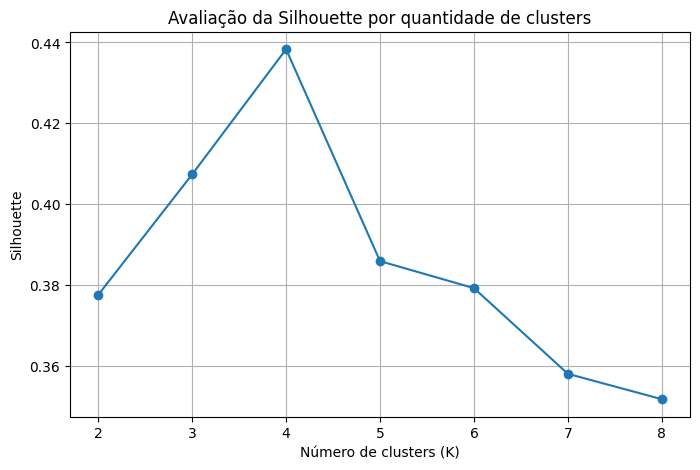

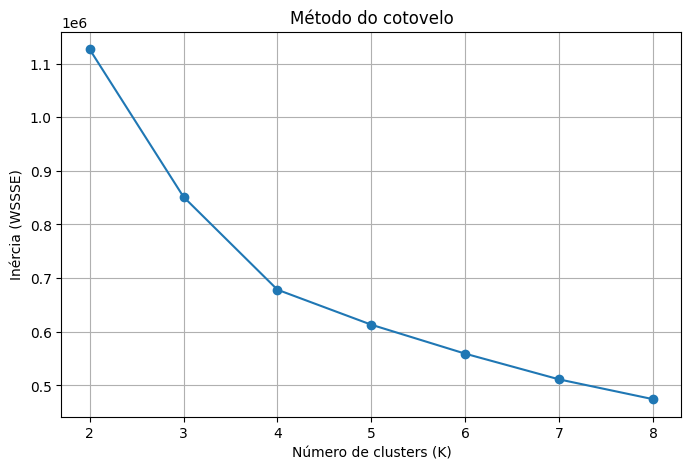

In [34]:
# Converter apenas os pequenos resultados para uma lista local
ks = [r[0] for r in resultados]
silhouettes = [r[1] for r in resultados]
inercias = [r[2] for r in resultados]

# Gráfico da Silhouette
plt.figure(figsize=(8, 5))
plt.plot(ks, silhouettes, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Silhouette")
plt.title("Avaliação da Silhouette por quantidade de clusters")
plt.xticks(ks)
plt.grid(True)
plt.show()

# Gráfico da Inércia
plt.figure(figsize=(8, 5))
plt.plot(ks, inercias, marker="o")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (WSSSE)")
plt.title("Método do cotovelo")
plt.xticks(ks)
plt.grid(True)
plt.show()

O método do cotovelo foi utilizado para avaliar a relação entre a quantidade de clusters e a inércia (WSSSE) do modelo K-Means.

Conforme esperado, observou-se uma redução progressiva da inércia à medida que o número de clusters aumentou. Entretanto, essa redução foi mais expressiva entre K = 2 e K = 4. A partir de quatro clusters, a curva passou a apresentar um comportamento mais gradual, indicando que o acréscimo de novos grupos proporcionou ganhos proporcionalmente menores na redução da dispersão interna.

Dessa forma, o gráfico sugere um ponto de inflexão próximo de K = 4, reforçando a escolha dessa configuração para o modelo.

In [38]:
modelo_final = modelos[4]
previsoes = modelo_final.transform(df_preparado)

In [39]:
perfil_clusters = (
    previsoes
    .groupBy("prediction")
    .agg(
        F.count("*").alias("QTD_SECOES"),
        F.avg("PERC_CANDIDATO_22").alias("MEDIA_CANDIDATO_22"),
        F.avg("PERC_BRANCOS").alias("MEDIA_BRANCOS"),
        F.avg("PERC_NULOS").alias("MEDIA_NULOS")
    )
    .orderBy("prediction")
)

perfil_clusters.show(truncate=False)

+----------+----------+-------------------+--------------------+--------------------+
|prediction|QTD_SECOES|MEDIA_CANDIDATO_22 |MEDIA_BRANCOS       |MEDIA_NULOS         |
+----------+----------+-------------------+--------------------+--------------------+
|0         |98919     |0.46726155014667986|0.010703292045320981|0.03819003852669118 |
|1         |166691    |0.619099165185552  |0.007964576059880971|0.01478754917767069 |
|2         |102110    |0.5169347478022339 |0.021915706718491107|0.020557455934751476|
|3         |131485    |0.2798570839799796 |0.00675115195844627 |0.016444495442671545|
+----------+----------+-------------------+--------------------+--------------------+



## Interpretação e caracterização dos clusters
Após a definição de quatro clusters, foi realizada a análise das médias das variáveis utilizadas na modelagem, juntamente com a quantidade de seções eleitorais pertencentes a cada grupo.

Os resultados demonstraram diferenças nos padrões de votação identificados pelo algoritmo.

O Cluster 0, composto por 98.919 seções, apresentou média de 46,73% de votos válidos para o candidato 22 e 53,27% para o candidato 13. Destacou-se também pelo maior percentual médio de votos nulos, correspondente a 3,82%.

O Cluster 1, que reuniu 166.691 seções, apresentou a maior média de votos válidos para o candidato 22, com 61,91%, enquanto o candidato 13 obteve média de 38,09%. Esse foi o maior grupo identificado pelo modelo.

O Cluster 2, composto por 102.110 seções, apresentou uma distribuição mais equilibrada entre os candidatos, com médias de 51,69% para o candidato 22 e 48,31% para o candidato 13. Também apresentou o maior percentual médio de votos brancos, de 2,19%.

Por fim, o Cluster 3, que reuniu 131.485 seções, apresentou a maior média de votos válidos para o candidato 13, correspondente a 72,01%, enquanto o candidato 22 obteve média de 27,99%.

De maneira geral, os resultados demonstram que o algoritmo identificou quatro padrões distintos de votação, diferenciados principalmente pela distribuição percentual dos votos válidos entre os candidatos e, complementarmente, pelos percentuais de votos brancos e nulos.

Esses agrupamentos permitem observar diferentes configurações de votação entre as seções eleitorais brasileiras, sem que isso implique necessariamente a existência de grupos territoriais homogêneos ou a identificação de comportamentos individuais dos eleitores.